## 1. Setup and Configurations

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Configure visual appearance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# OpenWeatherMap API settings
API_KEY = "YOUR_API_KEY_HERE"
CITY_NAME = "London"

## 2. Fetching Weather Data (With Fallback for Simulation)

In [2]:
def get_weather_data(city, api_key):
    url = f"http://api.openweathermap.org/data/2.5/forecast?q={city}&appid={api_key}&units=metric"
    response = requests.get(url)
    if response.status_code == 200:
        return response.json()
    else:
        print(f"API request failed with status: {response.status_code}. Generating simulated data instead...")
        return generate_mock_data()

def generate_mock_data():
    np.random.seed(42)
    base_time = datetime.now()
    list_data = []
    for i in range(40):
        timestamp = base_time + timedelta(hours=i * 3)
        list_data.append({
            "dt": int(timestamp.timestamp()),
            "main": {
                "temp": round(np.random.normal(18, 5), 2),
                "humidity": int(np.random.uniform(40, 95))
            },
            "wind": {
                "speed": round(np.random.uniform(1, 10), 2)
            },
            "rain": {"3h": round(np.random.exponential(0.5), 2) if np.random.rand() > 0.7 else 0.0}
        })
    return {"list": list_data, "city": {"name": CITY_NAME, "coord": {"lat": 51.5074, "lon": -0.1278}}}

raw_data = get_weather_data(CITY_NAME, API_KEY)

API request failed with status: 401. Generating simulated data instead...


## 3. Data Extraction and Preprocessing

In [3]:
extracted_records = []

for entry in raw_data["list"]:
    record = {
        "datetime": datetime.fromtimestamp(entry["dt"]),
        "temperature": entry["main"]["temp"],
        "humidity": entry["main"]["humidity"],
        "wind_speed": entry["wind"]["speed"],
        "precipitation": entry.get("rain", {}).get("3h", 0.0)
    }
    extracted_records.append(record)

df = pd.DataFrame(extracted_records)
df["date"] = df["datetime"].dt.date

print("Data Preprocessing Complete. Initial Records:")
display(df.head())

Data Preprocessing Complete. Initial Records:


,datetime,temperature,humidity,wind_speed,precipitation,date
0,2026-11-15 20:48:34,20.48,80,6.39,0.00,2026-11-15
1,2026-11-15 23:48:34,17.31,48,1.52,0.46,2026-11-15
2,2026-11-16 02:48:34,15.10,50,3.74,0.00,2026-11-16
3,2026-11-16 05:48:34,15.37,63,3.62,0.00,2026-11-16
4,2026-11-16 08:48:34,15.86,60,5.10,0.11,2026-11-16


## 4. Data Aggregation & Analysis

In [4]:
daily_summary = df.groupby("date").agg(
    avg_temp=("temperature", "mean"),
    max_temp=("temperature", "max"),
    min_temp=("temperature", "min"),
    avg_humidity=("humidity", "mean"),
    avg_wind_speed=("wind_speed", "mean"),
    total_precipitation=("precipitation", "sum")
).reset_index()

display(daily_summary)

,date,avg_temp,max_temp,min_temp,avg_humidity,avg_wind_speed,total_precipitation
0,2026-11-15,18.895000,20.48,17.31,64.000000,3.955000,0.46
1,2026-11-16,15.353750,19.88,12.25,60.375000,4.416250,1.09
2,2026-11-17,16.173750,22.44,10.08,69.750000,6.347500,2.13
3,2026-11-18,19.137500,23.21,10.91,66.500000,7.433750,0.50
4,2026-11-19,17.353750,20.02,8.41,62.250000,5.090000,0.14
5,2026-11-20,21.018333,26.53,13.99,61.666667,6.061667,0.00


## 5. Temperature and Wind Speed Visualizations

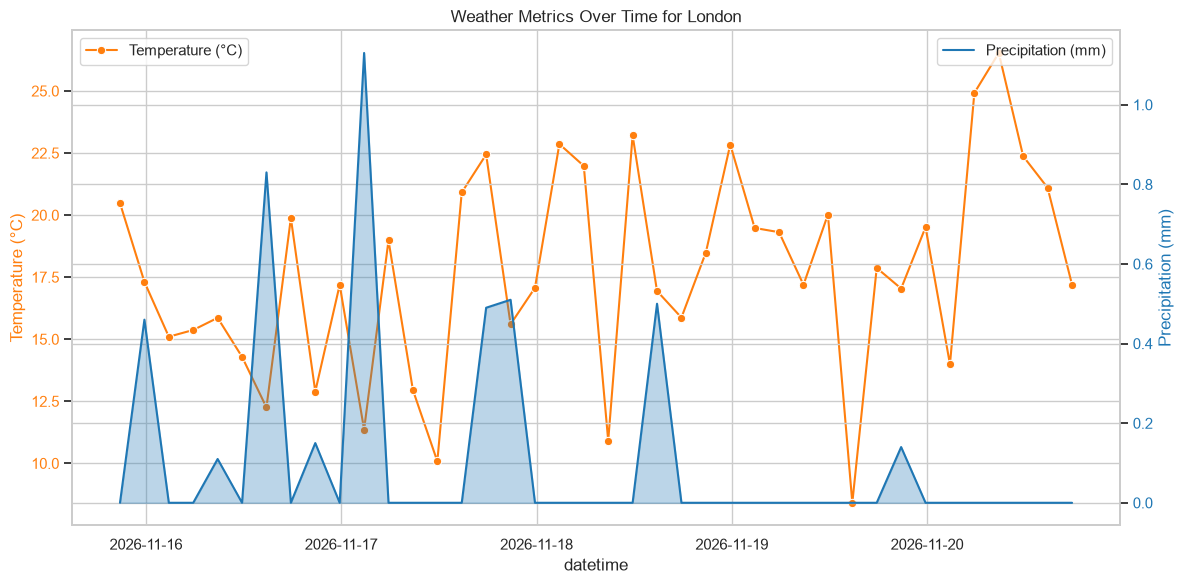

In [5]:
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.lineplot(data=df, x="datetime", y="temperature", ax=ax1, color="tab:orange", label="Temperature (°C)", marker="o")
ax1.set_ylabel("Temperature (°C)", color="tab:orange")
ax1.tick_params(axis="y", labelcolor="tab:orange")

ax2 = ax1.twinx()
# Using lineplot instead of barplot to match datetime coordinate systems correctly
sns.lineplot(data=df, x="datetime", y="precipitation", ax=ax2, color="tab:blue", label="Precipitation (mm)")
ax2.fill_between(df["datetime"], df["precipitation"], color="tab:blue", alpha=0.3)
ax2.set_ylabel("Precipitation (mm)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")

plt.title(f"Weather Metrics Over Time for {CITY_NAME}")
fig.tight_layout()
plt.show()

## 6. Correlation Analysis

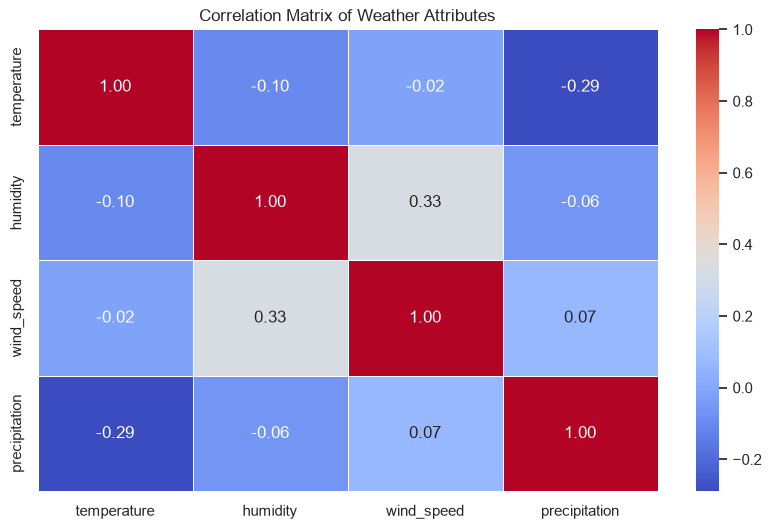

In [6]:
correlation_matrix = df[["temperature", "humidity", "wind_speed", "precipitation"]].corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Weather Attributes")
plt.show()